<a href="https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/02_red_una_capa_oculta_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 02 — Red con una capa oculta: Sigmoide vs. ReLU (NumPy)

**Curso:** Deep Learning – Conceptos · Especialización en Inteligencia Artificial · Universidad de Cundinamarca
**Semana 2:** backpropagation matricial y funciones de activación.

Arquitectura: $\;2 \rightarrow h \rightarrow 1\;$. La capa oculta usa **sigmoide** o **ReLU** (configurable) y la
salida usa **sigmoide** con pérdida BCE. El forward y el backward se escriben de forma **matricial** (sin bucles
sobre muestras ni neuronas) y el entrenamiento es por descenso de gradiente *full-batch*.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/02_red_una_capa_oculta_numpy.ipynb)

In [2]:
# ============================================================
# 0. Importaciones, semilla y dataset (mismo de Notebook 01)
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
FIG_DIR = "figuras"
os.makedirs(FIG_DIR, exist_ok=True)

X, y = make_moons(n_samples=1000, noise=0.20, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Las etiquetas se convierten a vectores columna (m, 1) para operar matricialmente
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)
print("X_train:", X_train.shape, "y_train:", y_train.shape)

X_train: (800, 2) y_train: (800, 1)


## 1. Ecuaciones del modelo

**Forward** (para un lote $X \in \mathbb{R}^{m\times 2}$):

$$ Z^{[1]} = XW^{[1]} + b^{[1]}, \quad A^{[1]} = g(Z^{[1]}), \quad Z^{[2]} = A^{[1]}W^{[2]} + b^{[2]}, \quad \hat{Y} = \sigma(Z^{[2]}) $$

**Backward** (regla de la cadena, pérdida BCE promediada):

$$ dZ^{[2]} = \hat{Y} - Y, \quad dW^{[2]} = \tfrac{1}{m}A^{[1]\top}dZ^{[2]}, \quad db^{[2]} = \tfrac{1}{m}\textstyle\sum dZ^{[2]} $$
$$ dA^{[1]} = dZ^{[2]}W^{[2]\top}, \quad dZ^{[1]} = dA^{[1]} \odot g'(Z^{[1]}), \quad dW^{[1]} = \tfrac{1}{m}X^\top dZ^{[1]}, \quad db^{[1]} = \tfrac{1}{m}\textstyle\sum dZ^{[1]} $$

con $g'(z)=\sigma(z)(1-\sigma(z))$ para sigmoide y $g'(z)=\mathbb{1}[z>0]$ para ReLU.

In [3]:
# ============================================================
# 1. Funciones de activación y sus derivadas
# ============================================================
def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def d_sigmoide(z):
    s = sigmoide(z)
    return s * (1.0 - s)            # máximo 0.25 en z = 0

def relu(z):
    return np.maximum(0.0, z)

def d_relu(z):
    return (z > 0).astype(float)    # 1 para z > 0, 0 en otro caso

ACTIVACIONES = {"sigmoide": (sigmoide, d_sigmoide), "relu": (relu, d_relu)}


def bce(Y, Y_hat, eps=1e-12):
    Y_hat = np.clip(Y_hat, eps, 1 - eps)
    return -np.mean(Y * np.log(Y_hat) + (1 - Y) * np.log(1 - Y_hat))

In [4]:
# ============================================================
# 2. Red con una capa oculta (implementación matricial)
# ============================================================
class RedUnaCapaOculta:
    def __init__(self, n_entradas, n_ocultas, activacion="relu", lr=0.1, seed=SEED):
        rng = np.random.default_rng(seed)
        self.g, self.dg = ACTIVACIONES[activacion]
        self.nombre = activacion
        # Inicialización: He para ReLU, Xavier/Glorot para sigmoide
        escala1 = np.sqrt(2.0 / n_entradas) if activacion == "relu" else np.sqrt(1.0 / n_entradas)
        self.W1 = rng.normal(0, escala1, size=(n_entradas, n_ocultas))
        self.b1 = np.zeros((1, n_ocultas))
        self.W2 = rng.normal(0, np.sqrt(1.0 / n_ocultas), size=(n_ocultas, 1))
        self.b2 = np.zeros((1, 1))
        self.lr = lr

    def forward(self, X):
        Z1 = X @ self.W1 + self.b1
        A1 = self.g(Z1)
        Z2 = A1 @ self.W2 + self.b2
        A2 = sigmoide(Z2)
        self.cache = (X, Z1, A1, A2)          # se guardan para el backward pass
        return A2

    def backward(self, Y):
        X, Z1, A1, A2 = self.cache
        m = X.shape[0]
        dZ2 = A2 - Y                               # (m, 1)
        dW2 = A1.T @ dZ2 / m                       # (h, 1)
        db2 = dZ2.mean(axis=0, keepdims=True)      # (1, 1)
        dA1 = dZ2 @ self.W2.T                      # (m, h)
        dZ1 = dA1 * self.dg(Z1)                    # (m, h)  <- aquí actúa g'(z)
        dW1 = X.T @ dZ1 / m                        # (2, h)
        db1 = dZ1.mean(axis=0, keepdims=True)      # (1, h)
        return dW1, db1, dW2, db2

    def fit(self, X, Y, X_val, Y_val, epochs=2000, cada=200):
        self.historial = {"loss": [], "val_loss": [], "acc": [], "val_acc": [], "factor_dg": []}
        for epoch in range(1, epochs + 1):
            A2 = self.forward(X)
            dW1, db1, dW2, db2 = self.backward(Y)
            # Descenso de gradiente
            self.W1 -= self.lr * dW1; self.b1 -= self.lr * db1
            self.W2 -= self.lr * dW2; self.b2 -= self.lr * db2
            # Registro de métricas
            A2_val = self.predict_proba(X_val)
            self.historial["loss"].append(bce(Y, A2))
            self.historial["val_loss"].append(bce(Y_val, A2_val))
            self.historial["acc"].append(np.mean((A2 >= 0.5) == Y))
            self.historial["val_acc"].append(np.mean((A2_val >= 0.5) == Y_val))
            self.historial["factor_dg"].append(self.dg(self.cache[1]).mean())   # media de g'(Z1)
            if epoch % cada == 0:
                print(f"[{self.nombre:8s}] época {epoch:4d} | loss {self.historial['loss'][-1]:.4f} "
                      f"| val_loss {self.historial['val_loss'][-1]:.4f} | val_acc {self.historial['val_acc'][-1]:.4f}")
        return self

    def predict_proba(self, X):
        A1 = self.g(X @ self.W1 + self.b1)
        return sigmoide(A1 @ self.W2 + self.b2)

    def predict(self, X, umbral=0.5):
        return (self.predict_proba(X) >= umbral).astype(int)

## 2. Entrenamiento comparativo

Se entrenan dos redes **idénticas** (16 neuronas ocultas, $\eta = 0.5$, 2000 épocas) que solo difieren en la
activación de la capa oculta.

In [5]:
modelos = {}
for act in ["sigmoide", "relu"]:
    modelos[act] = RedUnaCapaOculta(2, 16, activacion=act, lr=0.5).fit(
        X_train, y_train, X_test, y_test, epochs=2000, cada=400
    )

print("\nResumen final:")
for act, mod in modelos.items():
    acc_tr = np.mean(mod.predict(X_train) == y_train)
    acc_te = np.mean(mod.predict(X_test) == y_test)
    print(f"  {act:8s} -> train acc {acc_tr:.4f} | test acc {acc_te:.4f} | loss final {mod.historial['loss'][-1]:.4f}")

# Época en la que cada modelo supera por primera vez 95 % de accuracy de validación
for act, mod in modelos.items():
    va = np.array(mod.historial["val_acc"])
    idx = np.argmax(va >= 0.95) + 1 if np.any(va >= 0.95) else None
    print(f"  {act:8s} -> alcanza 95 % de val_acc en la época: {idx}")

[sigmoide] época  400 | loss 0.3104 | val_loss 0.2177 | val_acc 0.9250
[sigmoide] época  800 | loss 0.2980 | val_loss 0.2100 | val_acc 0.9250
[sigmoide] época 1200 | loss 0.2355 | val_loss 0.1655 | val_acc 0.9450
[sigmoide] época 1600 | loss 0.1693 | val_loss 0.1166 | val_acc 0.9600
[sigmoide] época 2000 | loss 0.1375 | val_loss 0.0926 | val_acc 0.9700
[relu    ] época  400 | loss 0.0932 | val_loss 0.0569 | val_acc 0.9900
[relu    ] época  800 | loss 0.0748 | val_loss 0.0393 | val_acc 0.9900
[relu    ] época 1200 | loss 0.0692 | val_loss 0.0340 | val_acc 0.9900
[relu    ] época 1600 | loss 0.0669 | val_loss 0.0310 | val_acc 0.9900
[relu    ] época 2000 | loss 0.0656 | val_loss 0.0297 | val_acc 0.9900

Resumen final:
  sigmoide -> train acc 0.9575 | test acc 0.9700 | loss final 0.1375
  relu     -> train acc 0.9762 | test acc 0.9900 | loss final 0.0656
  sigmoide -> alcanza 95 % de val_acc en la época: 1227
  relu     -> alcanza 95 % de val_acc en la época: 56


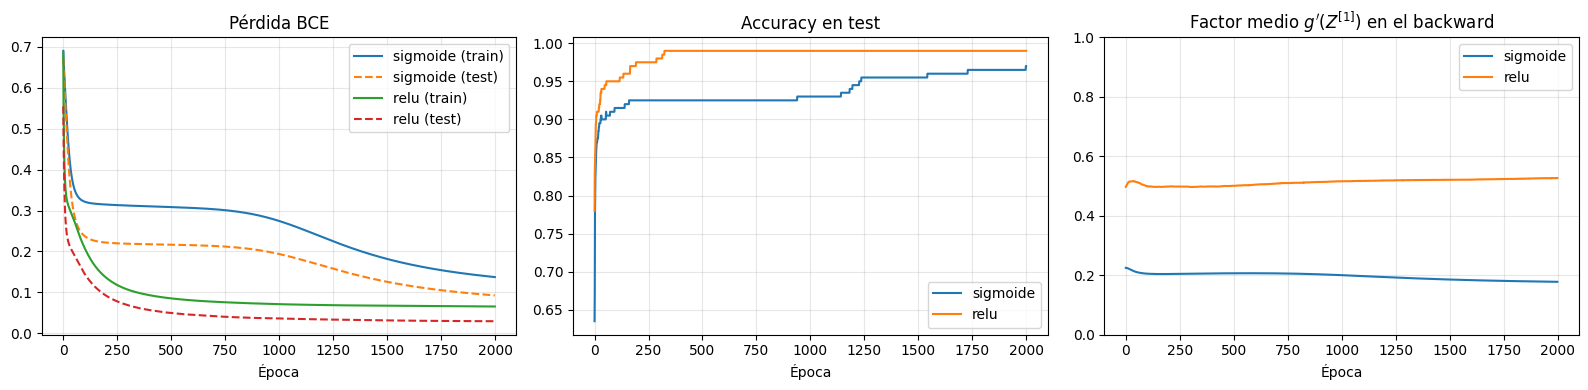

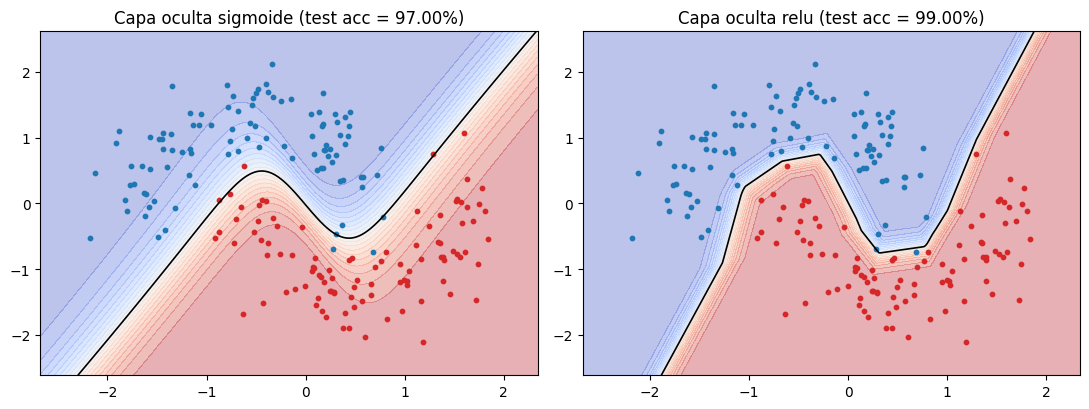

In [6]:
# ============================================================
# 3. Gráficas: pérdida, accuracy, factor g'(z) y fronteras
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for act, mod in modelos.items():
    axes[0].plot(mod.historial["loss"], label=f"{act} (train)")
    axes[0].plot(mod.historial["val_loss"], "--", label=f"{act} (test)")
    axes[1].plot(mod.historial["val_acc"], label=act)
    axes[2].plot(mod.historial["factor_dg"], label=act)
axes[0].set_title("Pérdida BCE"); axes[0].set_xlabel("Época")
axes[1].set_title("Accuracy en test"); axes[1].set_xlabel("Época")
axes[2].set_title(r"Factor medio $g'(Z^{[1]})$ en el backward"); axes[2].set_xlabel("Época"); axes[2].set_ylim(0, 1)
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_sigmoide_vs_relu_curvas.png", dpi=150); plt.show()


def graficar_frontera(ax, predict_fn, X, y, titulo):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 300),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 300))
    zz = predict_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.35)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=1.2)
    y = y.ravel()
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=10, c="tab:blue")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=10, c="tab:red")
    ax.set_title(titulo)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (act, mod) in zip(axes, modelos.items()):
    acc = np.mean(mod.predict(X_test) == y_test)
    graficar_frontera(ax, mod.predict_proba, X_test, y_test, f"Capa oculta {act} (test acc = {acc:.2%})")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_fronteras_una_capa.png", dpi=150); plt.show()

## 3. Análisis

- Con una sola capa oculta ambas redes aprenden una **frontera curva** y superan ampliamente al perceptrón
  lineal del Notebook 01.
- Con el mismo $\eta$ y el mismo número de épocas, **ReLU converge más rápido**: su derivada vale 1 en la
  región activa, mientras que la derivada de la sigmoide está acotada por 0.25. La tercera gráfica muestra el
  factor medio $g'(Z^{[1]})$ por el que se multiplica el gradiente al atravesar la capa oculta: con sigmoide
  nunca supera 0.25; con ReLU equivale a la fracción de neuronas activas (cercana a 0.5). En redes profundas ese factor se multiplica capa a capa y
  produce el **gradiente desvanecido**.
- La sigmoide se mantiene en la **capa de salida** porque su rango $(0,1)$ permite interpretar la salida como
  probabilidad y combina de forma exacta con BCE ($dZ^{[2]} = \hat{Y}-Y$).

In [7]:
!zip -r resultados.zip figuras
from google.colab import files
files.download("resultados.zip")

  adding: figuras/ (stored 0%)
  adding: figuras/02_fronteras_una_capa.png (deflated 7%)
  adding: figuras/02_sigmoide_vs_relu_curvas.png (deflated 10%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>